# Біфуркація в моделі Wolf–Sheep

**Дослідницьке питання:** як `wolf-efficiency` змінює довготривалий режим системи?

Експеримент містить 20 незалежних повторів для кожного цілого значення
`wolf-efficiency` від 1 до 20. Початкові умови фіксовані: 250 овець і
25 вовків. Максимальна тривалість — 1500 тактів.

Два технічні результати (`total collapse` та `overgrazing collapse`)
об'єднуємо в один змістовний режим: **колапс після вимирання вовків**.

In [1]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 120,
})

data_candidates = [
    Path('../experiments/4/table.csv'),       # запуск з папки analysis/
    Path('experiment4/table.csv'),            # локальна перевірка notebook
    Path('./table.csv'),
]
DATA_PATH = next(path for path in data_candidates if path.is_file())

with DATA_PATH.open(encoding='utf-8-sig', newline='') as handle:
    header = next(i for i, row in enumerate(csv.reader(handle)) if '[run number]' in row)

raw = pd.read_csv(DATA_PATH, skiprows=header)
df = raw.rename(columns={
    '[run number]': 'run',
    '[step]': 'step',
    'wolf-efficiency': 'efficiency',
    'count wolves': 'wolves',
    'count sheep': 'sheep',
    'sum [ grass ] of patches': 'grass',
})

regime_names = {
    'total collapse': 'Колапс після вимирання вовків',
    'overgrazing collapse': 'Колапс після вимирання вовків',
    'dynamic equilibrium': 'Динамічна рівновага',
    'wolves ate all sheep': 'Вовки з’їли всіх овець',
}
regime_order = [
    'Колапс після вимирання вовків',
    'Динамічна рівновага',
    'Вовки з’їли всіх овець',
]
colors = {
    regime_order[0]: '#d97706',
    regime_order[1]: '#16a34a',
    regime_order[2]: '#dc2626',
}
df['regime'] = df['outcome'].map(regime_names)
df['grass_share'] = df['grass'] / (35 * 35 * 10)

assert len(df) == 400
assert df.run.nunique() == 400
assert df.groupby('efficiency').size().eq(20).all()
assert df.regime.notna().all()
assert df[['efficiency', 'ticks', 'wolves', 'sheep', 'grass']].notna().all().all()

df.head()

,run,initial-sheep,initial-wolves,efficiency,step,outcome,ticks,wolves,sheep,grass,regime,grass_share
0,2,250,25,2,764,total collapse,764,0,0,0.0,Колапс після вимирання вовків,0.0
1,1,250,25,1,812,total collapse,812,0,0,0.0,Колапс після вимирання вовків,0.0
2,3,250,25,3,999,total collapse,999,0,0,0.0,Колапс після вимирання вовків,0.0
3,7,250,25,7,1288,total collapse,1288,0,0,0.0,Колапс після вимирання вовків,0.0
4,8,250,25,8,1500,dynamic equilibrium,1500,10,7,0.0,Динамічна рівновага,0.0


## Ймовірність трьох режимів

Для кожного значення параметра рахуємо частку повторів, що завершилися
кожним із трьох режимів. Сума трьох часток для кожного значення дорівнює 1.

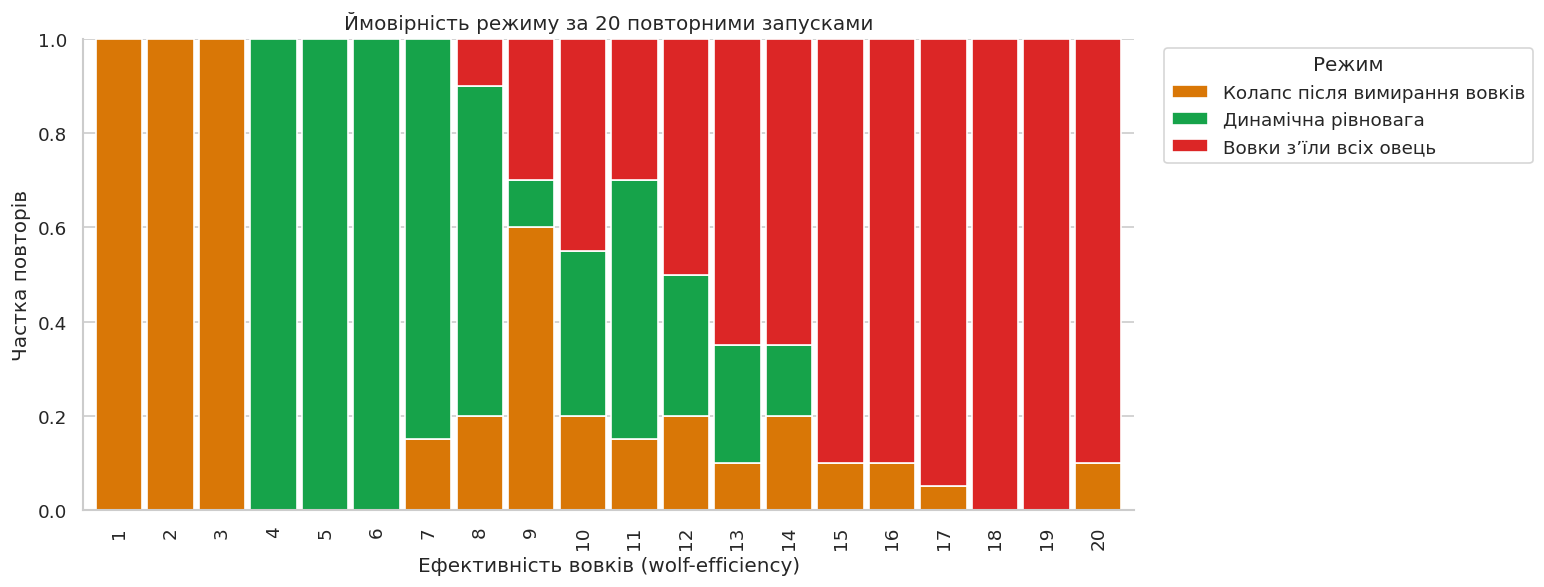

regime,Колапс після вимирання вовків,Динамічна рівновага,Вовки з’їли всіх овець
efficiency,,,
1,20,0,0
2,20,0,0
3,20,0,0
4,0,20,0
5,0,20,0
6,0,20,0
7,3,17,0
8,4,14,2
9,12,2,6


In [2]:
counts = pd.crosstab(df.efficiency, df.regime).reindex(columns=regime_order, fill_value=0)
probabilities = counts.div(counts.sum(axis=1), axis=0)
assert np.allclose(probabilities.sum(axis=1), 1)

ax = probabilities.plot(
    kind='bar', stacked=True, figsize=(13, 5), width=0.9,
    color=[colors[name] for name in regime_order],
)
ax.set(
    xlabel='Ефективність вовків (wolf-efficiency)',
    ylabel='Частка повторів',
    title='Ймовірність режиму за 20 повторними запусками',
    ylim=(0, 1),
)
ax.legend(title='Режим', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

counts

## Де проходять переходи?

Домінантним називаємо найчастіший режим для певного значення параметра.
Стовпець `probability` показує, наскільки відтворюваним є цей результат.

In [3]:
dominant = pd.DataFrame({
    'dominant_regime': probabilities.idxmax(axis=1),
    'probability': probabilities.max(axis=1),
})
dominant['robust_90pct'] = dominant.probability >= 0.90
display(dominant)

print('Значення з однозначним результатом (≥ 90% повторів):')
for regime in regime_order:
    values = dominant.index[(dominant.dominant_regime == regime) & dominant.robust_90pct].tolist()
    print(f'• {regime}: {values}')

,dominant_regime,probability,robust_90pct
efficiency,,,
1,Колапс після вимирання вовків,1.00,True
2,Колапс після вимирання вовків,1.00,True
3,Колапс після вимирання вовків,1.00,True
4,Динамічна рівновага,1.00,True
5,Динамічна рівновага,1.00,True
6,Динамічна рівновага,1.00,True
7,Динамічна рівновага,0.85,False
8,Динамічна рівновага,0.70,False
9,Колапс після вимирання вовків,0.60,False


Значення з однозначним результатом (≥ 90% повторів):
• Колапс після вимирання вовків: [1, 2, 3]
• Динамічна рівновага: [4, 5, 6]
• Вовки з’їли всіх овець: [15, 16, 17, 18, 19, 20]


## Фінальні популяції

Кожна точка — один запуск. Колір показує режим, до якого перейшла система.
Розкид за однакового `wolf-efficiency` є наслідком стохастичності ABM.

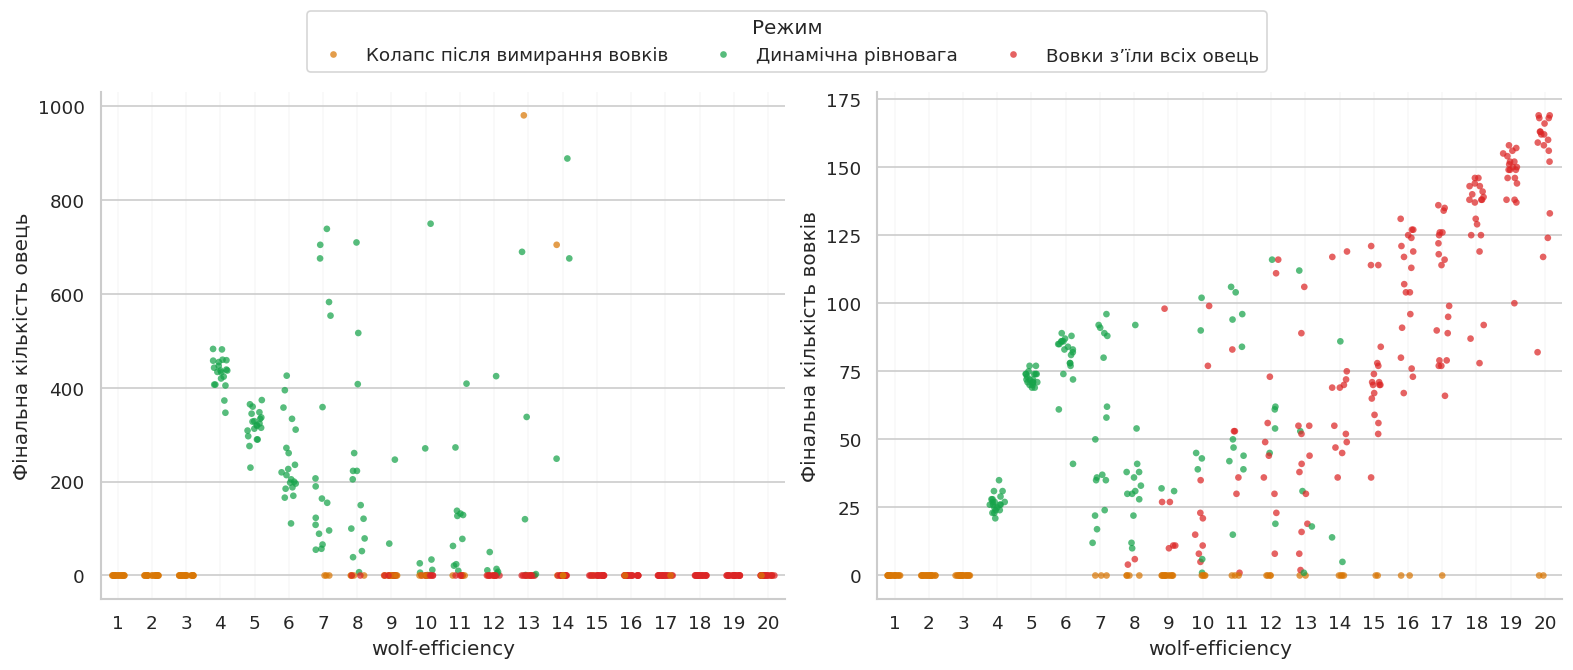

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)

for ax, metric, label in [
    (axes[0], 'sheep', 'Фінальна кількість овець'),
    (axes[1], 'wolves', 'Фінальна кількість вовків'),
]:
    sns.stripplot(
        data=df, x='efficiency', y=metric, hue='regime',
        hue_order=regime_order, palette=colors, jitter=0.22,
        alpha=0.72, size=4, ax=ax,
    )
    ax.set(xlabel='wolf-efficiency', ylabel=label)
    ax.grid(axis='x', alpha=0.12)
    ax.get_legend().remove()

handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, title='Режим', loc='lower center',
           bbox_to_anchor=(0.5, 1.01), ncols=3)
plt.show()

## Висновок

Модель демонструє не один плавний тренд, а перехід між трьома якісно
різними режимами. За низької ефективності вовки зникають і система
колапсує через надмірний випас. У середньому діапазоні три компоненти
співіснують. За високої ефективності вовки винищують овець.

Біля меж переходів результат не детермінований: однаковий параметр може
дати різні режими. Тому біфуркацію в стохастичній ABM потрібно описувати
ймовірностями, а не одним показовим запуском.